In [3]:
import os
import numpy as np
import pandas as pd
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Rescaling
import matplotlib.pyplot as plt

In [4]:
!git clone --depth 1 https://github.com/spMohanty/PlantVillage-Dataset.git

fatal: destination path 'PlantVillage-Dataset' already exists and is not an empty directory.


In [5]:
DATA_DIR = "/content/PlantVillage-Dataset/raw/color"

print("Dataset folder found:", os.path.exists(DATA_DIR))

print("Tomato folders:")
for folder in os.listdir(DATA_DIR):
    if folder.startswith("Tomato___"):
        print(folder)

Dataset folder found: True
Tomato folders:
Tomato___Late_blight
Tomato___Tomato_Yellow_Leaf_Curl_Virus
Tomato___Early_blight
Tomato___Tomato_mosaic_virus
Tomato___Target_Spot
Tomato___Leaf_Mold
Tomato___Septoria_leaf_spot
Tomato___Bacterial_spot
Tomato___healthy
Tomato___Spider_mites Two-spotted_spider_mite


In [6]:
import os

DATA_DIR = "/content/PlantVillage-Dataset/raw/color"

SELECTED_DIR = "/content/tomato_only"

os.makedirs(SELECTED_DIR, exist_ok=True)

tomato_classes = [
    "Tomato___healthy",
    "Tomato___Early_blight",
    "Tomato___Late_blight",
    "Tomato___Leaf_Mold"
]

In [7]:
# Connect each original folder to our selected folder
for name in tomato_classes:
    source = os.path.join(DATA_DIR, name)
    destination = os.path.join(SELECTED_DIR, name)

    if not os.path.isdir(source):
        raise FileNotFoundError("Folder not found: " + name)

    if not os.path.exists(destination):
        os.symlink(source, destination)

print("Four tomato classes are ready!")

Four tomato classes are ready!


In [8]:

IMG_SIZE = 180
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory(SELECTED_DIR, validation_split=0.2, subset="training", seed=123, image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE)


Found 5452 files belonging to 4 classes.
Using 4362 files for training.


In [9]:
# Load validation images
val_ds = keras.utils.image_dataset_from_directory(SELECTED_DIR, validation_split=0.2, subset="validation", seed=123, image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE
)
# Store disease names
class_names = train_ds.class_names

print("Disease names:", class_names)

Found 5452 files belonging to 4 classes.
Using 1090 files for validation.
Disease names: ['Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___healthy']


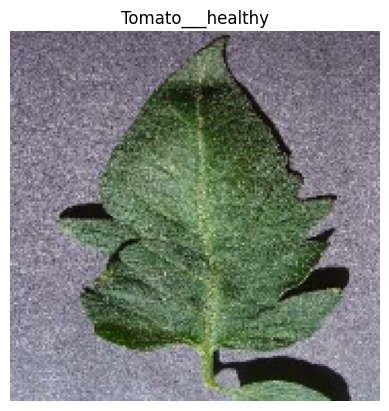

In [10]:
from PIL import Image

for images, labels in train_ds.take(1):


    image = images[0].numpy().astype("uint8")

    # Convert it into a Pillow image
    image = Image.fromarray(image)


    plt.imshow(image)
    plt.title(class_names[labels[0].numpy()])
    plt.axis("off")
    plt.show()

In [11]:
data_augmentation = keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.1),
    keras.layers.RandomZoom(0.1)
])

print("Data augmentation ready!")

Data augmentation ready!


In [12]:
model = keras.Sequential([

    keras.layers.Input(shape=(180, 180, 3)),

    data_augmentation,

    # Scale pixel values between 0 and 1
    keras.layers.Rescaling(1./255),

    # CNN layers
    keras.layers.Conv2D(32, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),


    keras.layers.Conv2D(64, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),


    keras.layers.Conv2D(128, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Flatten(),

    keras.layers.Dense(128, activation="relu"),

    keras.layers.Dense(4, activation="softmax")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,647,492 (25.36 MB)

 Trainable params: 6,647,492 (25.36 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model is ready for training!")

Model is ready for training!


In [34]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[early_stop]
)

Epoch 1/5
137/137 ━━━━━━━━━━━━━━━━━━━━ 403s 3s/step - accuracy: 0.8345 - loss: 0.3940 - val_accuracy: 0.8468 - val_loss: 0.4393
Epoch 2/5
137/137 ━━━━━━━━━━━━━━━━━━━━ 400s 3s/step - accuracy: 0.8737 - loss: 0.3359 - val_accuracy: 0.8624 - val_loss: 0.4223
Epoch 3/5
137/137 ━━━━━━━━━━━━━━━━━━━━ 443s 3s/step - accuracy: 0.8982 - loss: 0.2729 - val_accuracy: 0.8679 - val_loss: 0.3934
Epoch 4/5
137/137 ━━━━━━━━━━━━━━━━━━━━ 405s 3s/step - accuracy: 0.9028 - loss: 0.2517 - val_accuracy: 0.8771 - val_loss: 0.3958
Epoch 5/5
137/137 ━━━━━━━━━━━━━━━━━━━━ 422s 3s/step - accuracy: 0.9246 - loss: 0.2078 - val_accuracy: 0.8817 - val_loss: 0.4002


In [37]:
loss, accuracy = model.evaluate(val_ds)

print("Validation accuracy:", accuracy * 100, "%")

35/35 ━━━━━━━━━━━━━━━━━━━━ 25s 705ms/step - accuracy: 0.8679 - loss: 0.3934
Validation accuracy: 86.78898811340332 %


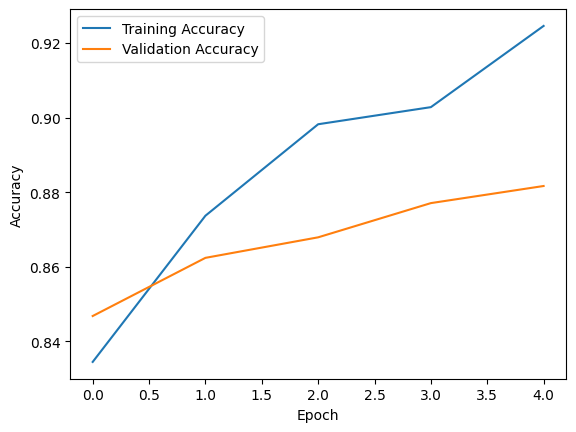

In [36]:
import matplotlib.pyplot as plt

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [17]:
from google.colab import files

# Upload one leaf photo
uploaded = files.upload()

filename = next(iter(uploaded))
image = Image.open(filename).convert("RGB")
image = image.resize((180, 180))
image_array = np.array(image)
image_array = np.expand_dims(image_array, axis=0)

# Predict the disease
prediction = model.predict(image_array)

#  highest probability
index = np.argmax(prediction[0])

print("Predicted disease:", class_names[index])
print("Confidence:", round(float(prediction[0][index] * 100), 2), "%")



Saving leaf 2.jpg to leaf 2.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step
Predicted disease: Tomato___Late_blight
Confidence: 94.68 %


In [18]:
results = pd.DataFrame({
    "Disease": class_names,
    "Probability (%)": prediction[0] * 100
})

print(results.sort_values(
    "Probability (%)",
    ascending=False
).to_string(index=False))

              Disease  Probability (%)
 Tomato___Late_blight        94.680695
Tomato___Early_blight         5.295758
   Tomato___Leaf_Mold         0.023500
     Tomato___healthy         0.000054


In [19]:
model.save("/content/tomato_disease_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [20]:
!pip install gradio

In [21]:
import gradio as gr

In [22]:
def predict_disease(image):
    image = image.convert("RGB")
    image = image.resize((180, 180))

    image_array = np.array(image)
    image_array = np.expand_dims(image_array, axis=0)

    predictions = model.predict(image_array, verbose=0)[0]

    results = {
        class_names[i].replace("Tomato__", "").replace("", " "):
        float(predictions[i])
        for i in range(len(class_names))
    }

    return results

print("Prediction function ready!")

Prediction function ready!


In [23]:
treatments = {
    "Tomato___healthy": "Plant looks healthy. Continue regular care.",
    "Tomato___Early_blight": "Remove affected leaves. Keep leaves dry.",
    "Tomato___Late_blight": "Check the plant promptly and consult an agricultural expert.",
    "Tomato___Leaf_Mold": "Improve airflow and avoid wetting leaves."
}

In [24]:
def predict_leaf(image):
    image = image.convert("RGB").resize((180, 180))
    image = np.array(image, dtype=np.float32)
    image = np.expand_dims(image, axis=0)

    prediction = model.predict(image, verbose=0)[0]
    index = np.argmax(prediction)

    disease = class_names[index]
    confidence = prediction[index] * 100

    advice = treatments.get(disease, "Consult an agricultural expert.")

    return (
        disease.replace("Tomato__", "").replace("", " "),
        f"Confidence: {confidence:.1f}%",
        advice
    )

In [25]:
prediction = np.array(prediction).flatten()

index = np.argmax(prediction)
confidence = float(prediction[index]) * 100

print("Index:", index)
print("Confidence:", confidence)

Index: 1
Confidence: 94.68069076538086


In [26]:
!pip install -q scikit-learn

In [27]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Load validation images in a fixed order
val_ds_fixed = keras.utils.image_dataset_from_directory(
    SELECTED_DIR,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(180, 180),
    batch_size=32,
    shuffle=False
)

# Get actual labels
y_true = np.concatenate([
    labels.numpy()
    for images, labels in val_ds_fixed
])

# Predict using the trained model
y_prob = model.predict(val_ds_fixed)
y_pred = np.argmax(y_prob, axis=1)

# Show evaluation results
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=val_ds_fixed.class_names,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3]
))

Found 5452 files belonging to 4 classes.
Using 1090 files for validation.
35/35 ━━━━━━━━━━━━━━━━━━━━ 44s 1s/step
                       precision    recall  f1-score   support

Tomato___Early_blight       0.00      0.00      0.00         0
 Tomato___Late_blight       0.00      0.00      0.00         0
   Tomato___Leaf_Mold       0.00      0.00      0.00         0
     Tomato___healthy       1.00      0.97      0.98      1090

             accuracy                           0.97      1090
            macro avg       0.25      0.24      0.25      1090
         weighted avg       1.00      0.97      0.98      1090

Confusion Matrix:
[[   0    0    0    0]
 [   0    0    0    0]
 [   0    0    0    0]
 [  11   18    5 1056]]


In [28]:
def estimate_severity(image):
    image = image.convert("RGB")
    pixels = list(image.getdata())

    total_pixels = len(pixels)
    brown_pixels = 0

    for r, g, b in pixels:
        if r > g and r > b and g < 150:
            brown_pixels += 1

    percentage = (brown_pixels / total_pixels) * 100

    if percentage < 5:
        severity = "Low"
    elif percentage < 20:
        severity = "Medium"
    else:
        severity = "High"

    return severity, round(percentage, 2)

In [29]:
severity, percentage = estimate_severity(image)

severity_result = (
    f"Estimated severity: {severity}\n"
    f"Brown pixels: {percentage}%"
)

In [30]:
def predict_leaf(image):
    image = image.convert("RGB")

    # Disease prediction
    resized_image = image.resize((180, 180))
    image_array = np.array(resized_image, dtype=np.float32)
    image_array = np.expand_dims(image_array, axis=0)

    prediction = model.predict(image_array, verbose=0)[0]
    index = np.argmax(prediction)

    disease = class_names[index]
    confidence = prediction[index] * 100
    advice = treatments.get(disease, "Consult an agricultural expert.")

    # Severity estimation using the same uploaded photo
    severity, percentage = estimate_severity(image)

    return (
        disease.replace("Tomato__", "").replace("", " "),
        f"Confidence: {confidence:.1f}%",
        advice,
        f"Estimated severity: {severity} ({percentage}%)"
    )

In [31]:
import gradio as gr

app = gr.Interface(
    fn=predict_leaf,
    inputs=gr.Image(type="pil"),
    outputs=[
        gr.Textbox(label="Predicted Disease"),
        gr.Textbox(label="Confidence"),
        gr.Textbox(label="Treatment Advice"),
        gr.Textbox(label="Estimated Severity")
    ],
    title="Tomato Disease Detection",
    examples=None
)

app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ea47ec0bb8d1742c16.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [32]:
model.save("/content/tomato_disease_model.keras")

print("Model saved successfully!")

Model saved successfully!
